#Import

In [4]:
from PIL import Image  # Import the Image module from Pillow
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier

#MNIST classification using CNN model

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 52s 34ms/step - accuracy: 0.9517 - loss: 0.1596 - val_accuracy: 0.9831 - val_loss: 0.0571
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 44s 30ms/step - accuracy: 0.9843 - loss: 0.0510 - val_accuracy: 0.9813 - val_loss: 0.0641
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 82s 29ms/step - accuracy: 0.9892 - loss: 0.0346 - val_accuracy: 0.9869 - val_loss: 0.0437
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 84s 31ms/step - accuracy: 0.9916 - loss: 0.0265 - val_accuracy: 0.9874 - val_loss: 0.0446
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 44s 29ms/step - accuracy: 0.9939 - loss: 0.0194 - val_accuracy: 0.9895 - val_loss: 0.0374
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


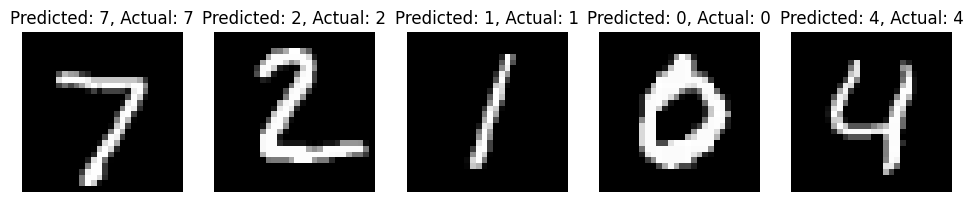

In [5]:
# Import Libraries
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Load the MNIST Dataset
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Preprocess the Data
x_train = x_train.reshape((60000, 28, 28, 1)).astype('float32') / 255.0
x_test = x_test.reshape((10000, 28, 28, 1)).astype('float32') / 255.0

# Build a Simple CNN Model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')  # 10 classes for digits 0-9
])

# Compile the Model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train the Model
model.fit(x_train, y_train, epochs=5, validation_split=0.2)

# Make Predictions on Test Set
predictions = model.predict(x_test)

# Display Sample Predictions
plt.figure(figsize=(12, 6))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {tf.argmax(predictions[i]).numpy()}, Actual: {y_test[i]}")
    plt.axis('off')
plt.show()


#Object Detection

In [7]:
# Set up the environment
!git clone https://github.com/ultralytics/yolov5  # Clone the YOLOv5 repo
%cd yolov5
!pip install -r requirements.txt  # Install requirements

# Import libraries
import torch
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load a pre-trained YOLOv5 model
model = torch.hub.load('ultralytics/yolov5:master', 'yolov5s')  # Load YOLOv5s model (small)


Cloning into 'yolov5'...
remote: Enumerating objects: 18806, done.
remote: Counting objects: 100% (357/357), done.
remote: Compressing objects: 100% (210/210), done.
remote: Total 18806 (delta 296), reused 147 (delta 147), pack-reused 18449 (from 2)
Receiving objects: 100% (18806/18806), 17.72 MiB | 10.34 MiB/s, done.
Resolving deltas: 100% (12816/12816), done.
/content/yolov5/yolov5
The repository ultralytics_yolov5 does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)?y
Downloading: "https://github.com/ultralytics/yolov5/zipball/master" to /root/.cache/torch/hub/master.zip
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOL

100%|██████████| 14.1M/14.1M [00:00<00:00, 138MB/s]


Fusing layers... 


YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


In [8]:
pip install requests


In [9]:
import requests

# Define the URL of the image
url = 'https://github.com/ultralytics/yolov5/releases/download/v1.0/zidane.jpg'

# Send a GET request to the URL
response = requests.get(url)

# Open a file in binary write mode
with open('zidane.jpg', 'wb') as f:
    f.write(response.content)

print("Image downloaded successfully!")


Image downloaded successfully!


YOLOv5 🚀 2026-10-25 Python-3.13.16 torch-2.11.0+cpu CPU



Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


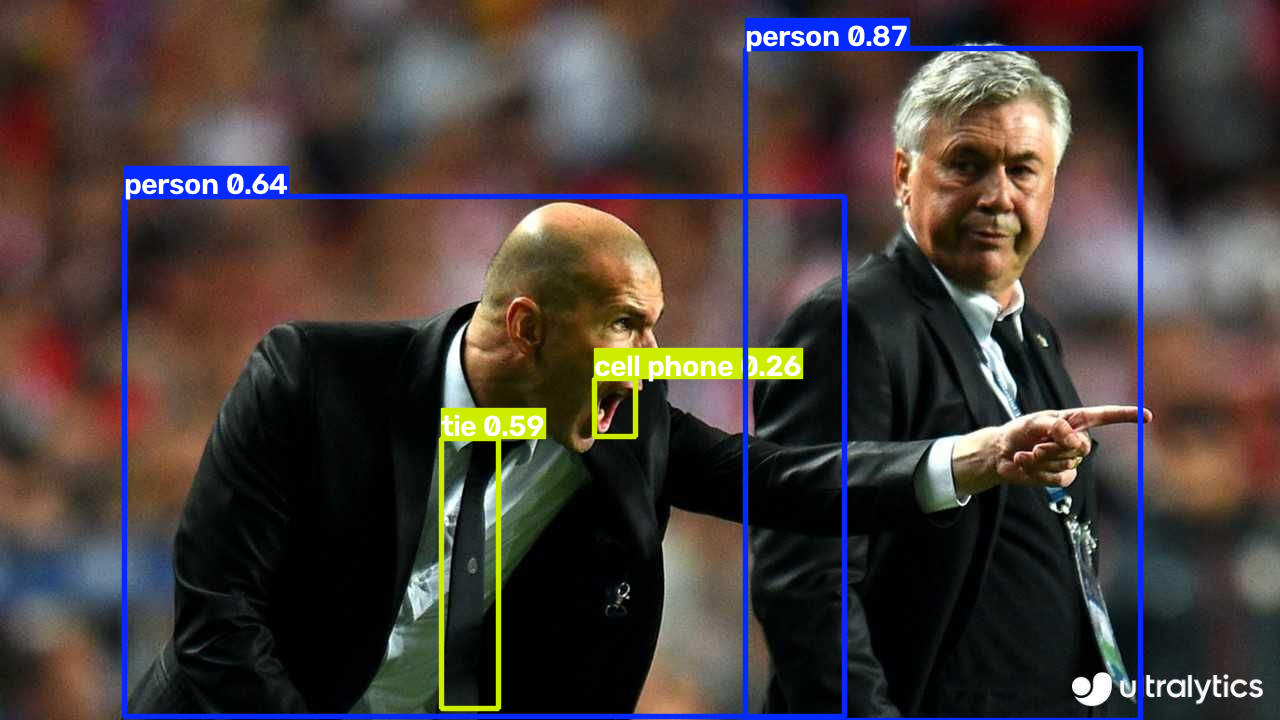

In [10]:
import torch

# Load the YOLOv5 model
model = torch.hub.load('ultralytics/yolov5:master', 'yolov5s')

# Load the image
img = 'zidane.jpg'  # path to your image

# Perform inference
results = model(img)

# Show results
results.show()  # This will display the image with detections


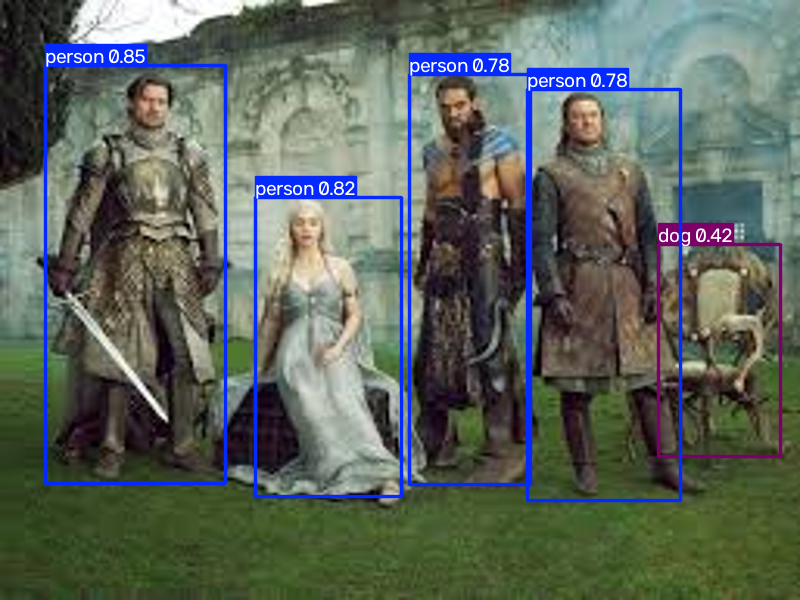

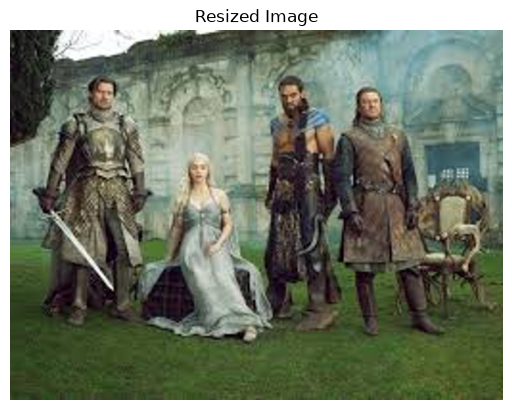

In [13]:
img_path = '/content/game of thrones.jpeg'  # path to your image
image = Image.open(img_path)

# Resize the image
resized_image = image.resize((800, 600))

# Convert the resized image to a format compatible with the model (e.g., NumPy array)
# If your model requires a specific input format, you may need to adjust the image further.
img_array = np.array(resized_image)

# Perform inference
results = model(img_array)

# Show results
results.show()  # This will display the image with detections

# If you want to visualize the resized image
plt.imshow(resized_image)
plt.axis('off')
plt.title('Resized Image')
plt.show()


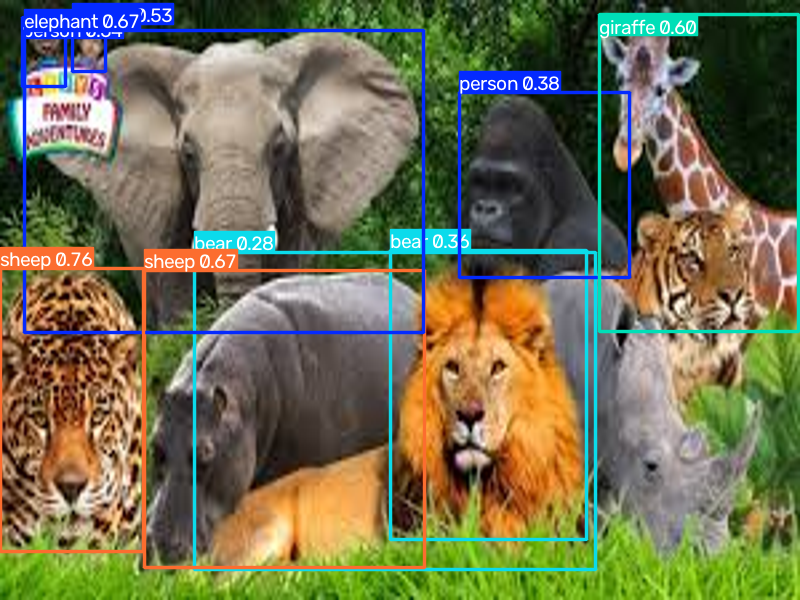

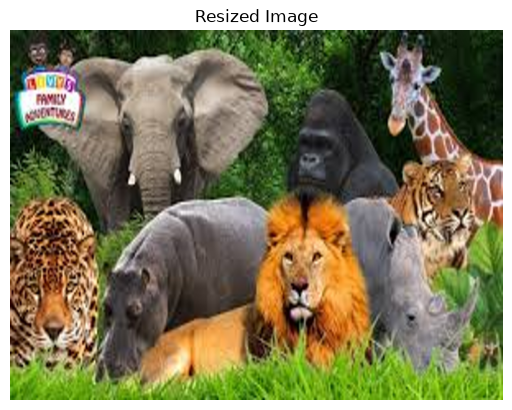

In [ ]:
img_path = '/content/animals.jpeg'  # path to your image
image = Image.open(img_path)

# Resize the image
resized_image = image.resize((800, 600))

# Convert the resized image to a format compatible with the model (e.g., NumPy array)
# If your model requires a specific input format, you may need to adjust the image further.
img_array = np.array(resized_image)

# Perform inference
results = model(img_array)

# Show results
results.show()  # This will display the image with detections

# If you want to visualize the resized image
plt.imshow(resized_image)
plt.axis('off')
plt.title('Resized Image')
plt.show()


#Segmentation

In [14]:
pip install tensorflow tensorflow-datasets matplotlib numpy


#HomeWork2

Run this cell first to load the required dataset

In [18]:
# Load the MNIST dataset from Keras as a reliable backup when OpenML is down (503 Service Unavailable)
import tensorflow as tf

# Load the pre-cached MNIST dataset
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.mnist.load_data()

# Combine and reshape into Scikit-learn format (samples, 784 features)
X = np.concatenate([x_train_raw, x_test_raw], axis=0)
X = X.reshape(X.shape[0], -1) / 255.0  # Normalize pixel values to [0, 1]

y = np.concatenate([y_train_raw, y_test_raw], axis=0)
y = y.astype(np.uint8)  # Convert labels to integers

# Split the Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the data for SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


##Part1 : In this section, we want to classify the MNIST dataset using Random Forest, Logistic Regression, and Neural Networks. We will print the accuracy for each model. The code for Random Forest will serve as an example, and you should complete the code for Logistic Regression and Neural Networks accordingly.

In [19]:
# Train Different Classifiers

# 1. Random Forest
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)
y_pred_rf = rf_classifier.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)


In [20]:
# 2. Logistic Regression
logistic_classifier = LogisticRegression(max_iter=200)
logistic_classifier.fit(X_train, y_train)

y_pred_logistic = logistic_classifier.predict(X_test)
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)


In [21]:
# 3. MLP (Neural Network)
mlp = MLPClassifier(max_iter=1000)
mlp.fit(X_train, y_train)

y_pred_mlp = mlp.predict(X_test)


accuracy_mlp = accuracy_score(y_test, y_pred_mlp)


In [22]:
# Step 6: Print Accuracy Results
print(f'Logistic Regression Accuracy: {accuracy_logistic * 100:.2f}%')
print(f'Random Forest Accuracy: {accuracy_rf * 100:.2f}%')
print(f'MLP Accuracy: {accuracy_mlp * 100:.2f}%')

Logistic Regression Accuracy: 91.90%
Random Forest Accuracy: 96.75%
MLP Accuracy: 97.19%


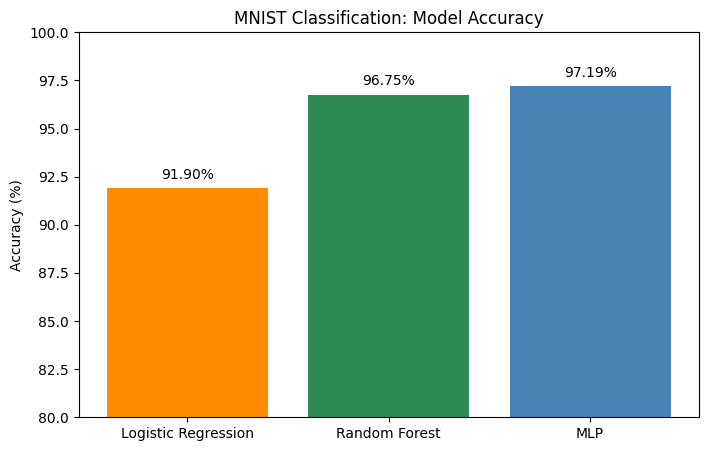

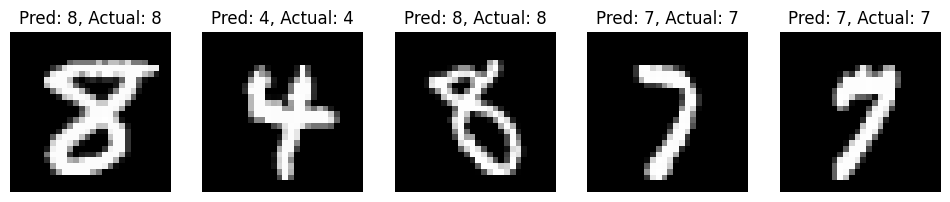

In [23]:
# Visualize the accuracy of the three models
model_names = ['Logistic Regression', 'Random Forest', 'MLP']
accuracies = [accuracy_logistic * 100, accuracy_rf * 100, accuracy_mlp * 100]

plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, accuracies, color=['darkorange', 'seagreen', 'steelblue'])
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2, acc + 0.5, f"{acc:.2f}%", ha='center')
plt.ylim(80, 100)
plt.title("MNIST Classification: Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.show()

# Show a few test digits with the MLP prediction
X_test_np = np.array(X_test)
y_test_np = np.array(y_test)
plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test_np[i].reshape(28, 28), cmap='gray')
    plt.title(f"Pred: {y_pred_mlp[i]}, Actual: {y_test_np[i]}")
    plt.axis('off')
plt.show()


## Part2: take a photo of yourself, upload it to the jupyter notebook and detect your face using Yolo model

image 1/1: 800x648 1 person
Speed: 3.1ms pre-process, 139.3ms inference, 0.8ms NMS per image at shape (1, 3, 640, 544)


     name  confidence
0  person     0.87412


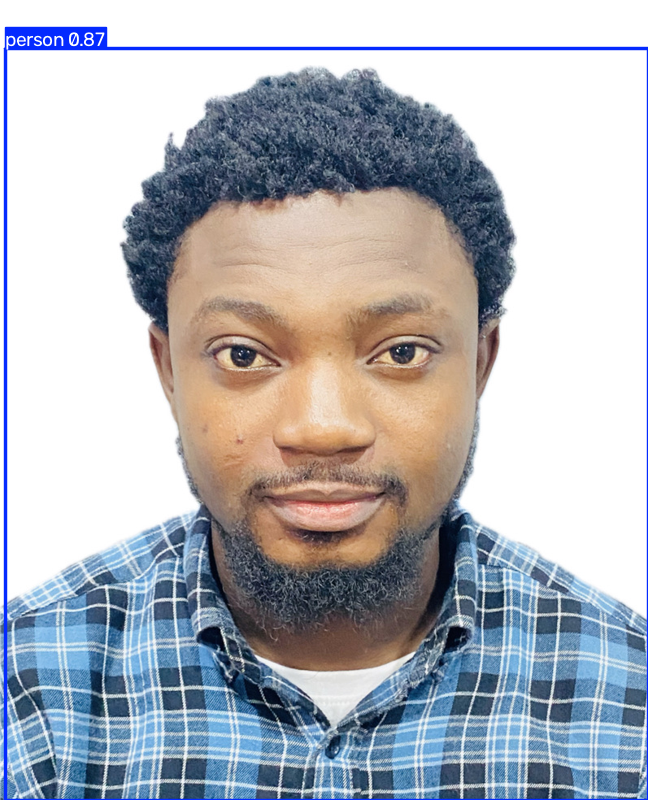

In [ ]:
# Detect my face with the YOLOv5 model loaded above
img_path = '/content/Bukola_headshot.jpeg'  # path to my photo
image = Image.open(img_path)

# Resize the image (keeping its proportions so the face isn't stretched)
image.thumbnail((800, 800))
img_array = np.array(image)

# Perform inference
results = model(img_array)

# Print what was detected and how confident the model is
results.print()
print(results.pandas().xyxy[0][['name', 'confidence']])

# Show results with the detection box
results.show()
